# Healthcare Analytics For Doctor Visits

**Domain**: Healthcare   
**Project Theme**: Healthcare Analytics for Doctor Visits   
**Tools**: Python, Pandas, NumPy, Matplotlib, Seaborn   
**Project Goal**:   
To analyze doctor-visit patterns and identify how illness, health status, chronic conditions, and patient characteristics are associated with recorded doctor visits, so management can identify areas for further investigation before making operational changes.


# Problem Statement  
Healthcare organizations need to understand patterns in doctor visits to support better operational planning.
This project analyzes patient healthcare data to identify groups with higher recorded doctor visits.
It examines how illness and health status are associated with visit frequency.
It also investigates whether chronic conditions correspond to different visit patterns.
The analysis aims to identify important factors that management should investigate before making operational changes.

# Project Objectives  

*  Understand the structure and characteristics of the healthcare dataset.
* Analyze the distribution of recorded doctor visits.
* Identify groups with higher recorded doctor visits.
* Examine the association between illness, health status, and doctor visits.
* Analyze whether chronic conditions correspond to different visit patterns.
* Identify factors that management should investigate before making operational changes.



# Dataset  
This dataset contains healthcare information related to patients and their recorded doctor visits. It includes variables such as visits, age, gender, illness, health status, income, insurance coverage, and chronic conditions, which can be analyzed to identify patterns in healthcare utilization.  
**Dataset File**:1776250375-P2-Healthcare Analytics for Doctor Visits.csv


In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f" {x:,.2f}")

In [ ]:
# Load the Dataset
file_path="/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv"
df=pd.read_csv(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


#Initial Data Understanding

In [ ]:
# Dataset shape
print("Number of rows:", df.shape[0])
print("number of columns:", df.shape[1])

Number of rows: 5190
number of columns: 13


In [ ]:
# Display the First 5 Rows
df.head(5)

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [ ]:
# Display the Last 5 Rows
df.tail(5)

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [ ]:
# Display Column Names
print(df.columns.tolist())

['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']


In [ ]:
# Data Types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [ ]:
# # Statistical Information of the Dataset
df.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,"5,190.00","5,190.00","5,190.00","5,190.00","5,190.00","5,190.00","5,190.00"
mean,"2,595.50",0.30,0.41,0.58,1.43,0.86,1.22
std,"1,498.37",0.80,0.20,0.37,1.38,2.89,2.12
min,1.00,0.00,0.19,0.00,0.00,0.00,0.00
25%,"1,298.25",0.00,0.22,0.25,0.00,0.00,0.00
50%,"2,595.50",0.00,0.32,0.55,1.00,0.00,0.00
75%,"3,892.75",0.00,0.62,0.90,2.00,0.00,2.00
max,"5,190.00",9.00,0.72,1.50,5.00,14.00,12.00


In [ ]:
# Categorical summary
df.describe(include="object")

,gender,private,freepoor,freerepat,nchronic,lchronic
count,5190,5190,5190,5190,5190,5190
unique,2,2,2,2,2,2
top,female,no,no,no,no,no
freq,2702,2892,4968,4099,3098,4585


In [ ]:
# Check Missing Values
df.isnull().sum()

,0
Unnamed: 0,0
visits,0
gender,0
age,0
income,0
illness,0
reduced,0
health,0
private,0
freepoor,0


#Data Cleaning
The dataset is checked for unnecessary columns, duplicate records, and missing values before performing exploratory and business-focused analysis.


In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()
# Remove the unnecessary index column
df_clean = df_clean.drop(columns=["Unnamed: 0"])

In [ ]:
#Column Name
df_clean.columns

Index(['visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health',
       'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic'],
      dtype='object')

In [ ]:
#Duplicate records
duplicate_count=df.duplicated().sum()
print("number of duplicate rows:",duplicate_count)

number of duplicate rows: 0


In [ ]:
#Check the final cleaned dataset size
df_clean.shape

(5190, 12)

#Univariate Analysis
Univariate analysis examines one variable at a time. It helps you understand the variable's distribution, frequency, range, or summary statistics before comparing it with another variable.

## Univariate Analysis: Distribution of Doctor Visits
This analysis examines the distribution of recorded doctor visits across the dataset. It helps identify how many records have zero visits and how frequently different visit counts occur.

In [ ]:
# Basic statistical for doctor visits
df_clean['visits'].describe()

,visits
count,"5,190.00"
mean,0.30
std,0.80
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,9.00


In [ ]:
#Check how many records have visits
df_clean['visits'].value_counts().sort_index()

,count
visits,
0,4141
1,782
2,174
3,30
4,24
5,9
6,12
7,12
8,5


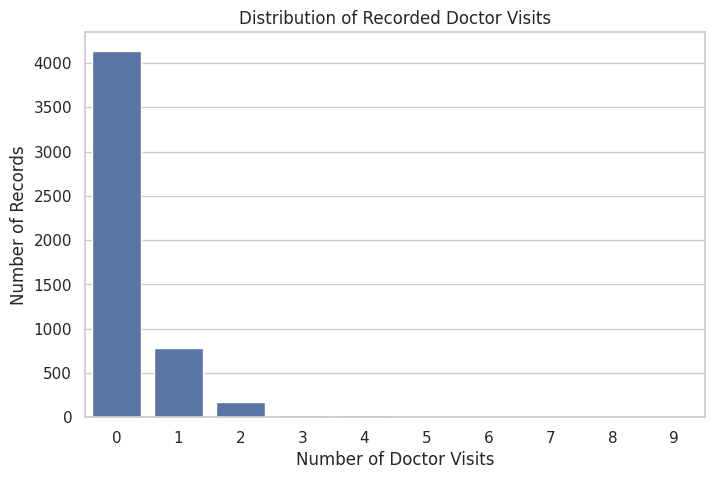

In [ ]:
# Visualization
plt.figure(figsize=(8,5))
sns.countplot(x='visits', data=df_clean)
plt.title('Distribution of Recorded Doctor Visits')
plt.xlabel('Number of Doctor Visits')
plt.ylabel('Number of Records')
plt.show()

## Univariate Analysis : Gender Distribution
This analysis examines the number and percentage of records in each gender category. It helps describe the gender composition of the dataset before comparing recorded doctor visits between groups.

In [ ]:
#Frequency count
df_clean['gender'].value_counts()

,count
gender,
female,2702
male,2488


In [ ]:
#Percentage distribution
df_clean['gender'].value_counts(normalize=True) * 100

,proportion
gender,
female,52.06
male,47.94


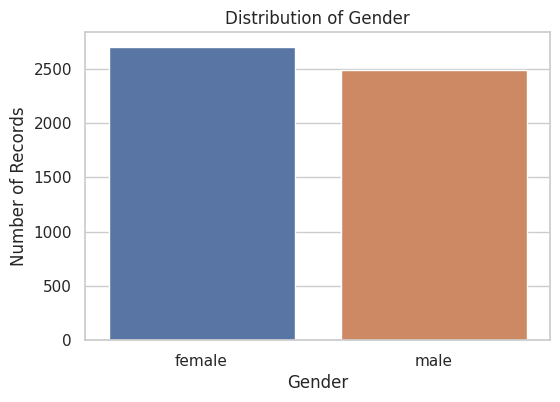

In [ ]:
# Visualization
plt.figure(figsize=(6, 4))
sns.countplot(
    data=df_clean,
    x="gender",
    hue="gender",
    legend=False
)
plt.title("Distribution of Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Records")
plt.show()

## Univariate Analysis: Age Distribution
This analysis examines the distribution of values recorded in the age variable. It helps identify the range and frequency of the dataset's age-related values before further analysis.

In [ ]:
df_clean['age'].describe()

,age
count,"5,190.00"
mean,0.41
std,0.20
min,0.19
25%,0.22
50%,0.32
75%,0.62
max,0.72


In [ ]:
#Check the actual age values
df_clean['age'].value_counts().sort_index()

,count
age,
0.19,752
0.22,1213
0.27,523
0.32,301
0.37,146
0.42,126
0.47,181
0.52,222
0.57,273


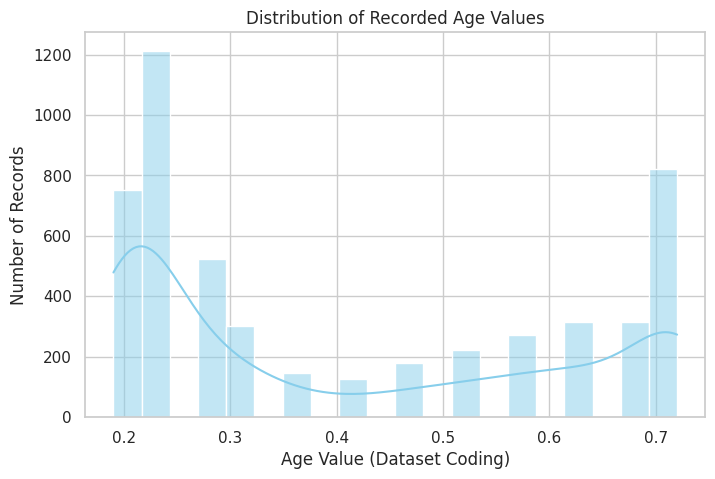

In [ ]:
# Visualization
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_clean,
    x="age",
    bins=20,
    kde=True,
    color="skyblue"
)
plt.title("Distribution of Recorded Age Values")
plt.xlabel("Age Value (Dataset Coding)")
plt.ylabel("Number of Records")
plt.show()

## Univariate Analysis: Income Distribution

In [ ]:
df_clean['income'].describe()

,income
count,"5,190.00"
mean,0.58
std,0.37
min,0.00
25%,0.25
50%,0.55
75%,0.90
max,1.50


In [ ]:
#Check the income values
df_clean['income'].value_counts().sort_index()

,count
income,
0.00,79
0.01,35
0.06,80
0.15,249
0.25,1195
0.35,462
0.45,400
0.55,467
0.65,455


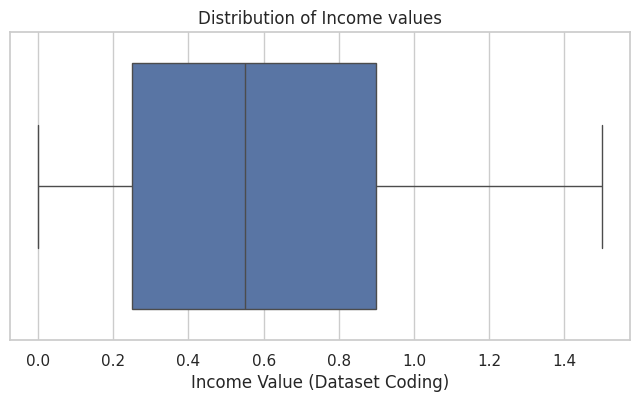

In [ ]:
# Visualization
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean['income'])
plt.title('Distribution of Income values')
plt.xlabel('Income Value (Dataset Coding)')
plt.show()

## Univariate Analysis : Illness Distribution
This analysis examines the frequency and percentage of records at each recorded illness level. It helps show which illness categories are most and least represented in the dataset.

In [ ]:
# Frequency of each illness level
df_clean['illness'].value_counts().sort_index()

,count
illness,
0,1554
1,1638
2,946
3,542
4,274
5,236


In [ ]:
#Percentage distribution
df_clean['illness'].value_counts(normalize=True).sort_index() * 100

,proportion
illness,
0,29.94
1,31.56
2,18.23
3,10.44
4,5.28
5,4.55


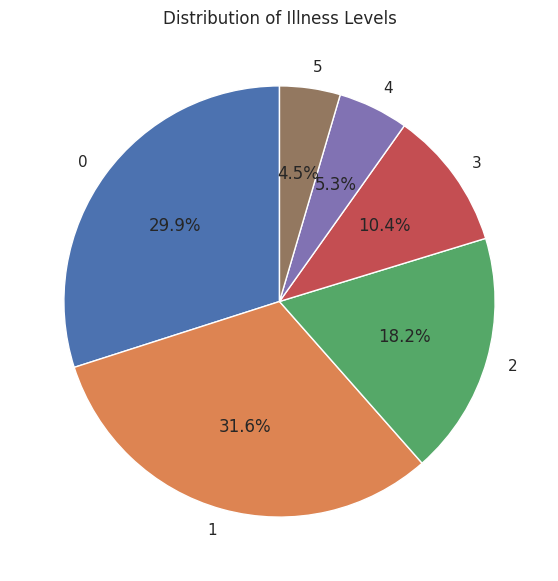

In [ ]:
#Visualization
illness_counts = df_clean['illness'].value_counts().sort_index()
plt.figure(figsize=(7,7))
plt.pie(
    illness_counts.values,
    labels=illness_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribution of Illness Levels')
plt.show()

## Univariate Analysis : Reduced Activity Distribution
This analysis examines the distribution of values in the reduced-activity variable. It helps show how often different levels of reduced activity are recorded across the dataset.

In [ ]:
df_clean['reduced'].describe()

,reduced
count,"5,190.00"
mean,0.86
std,2.89
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,14.00


In [ ]:
#Frequency distribution
df_clean['reduced'].value_counts().sort_index()

,count
reduced,
0,4454
1,177
2,108
3,74
4,45
5,40
6,17
7,38
8,17


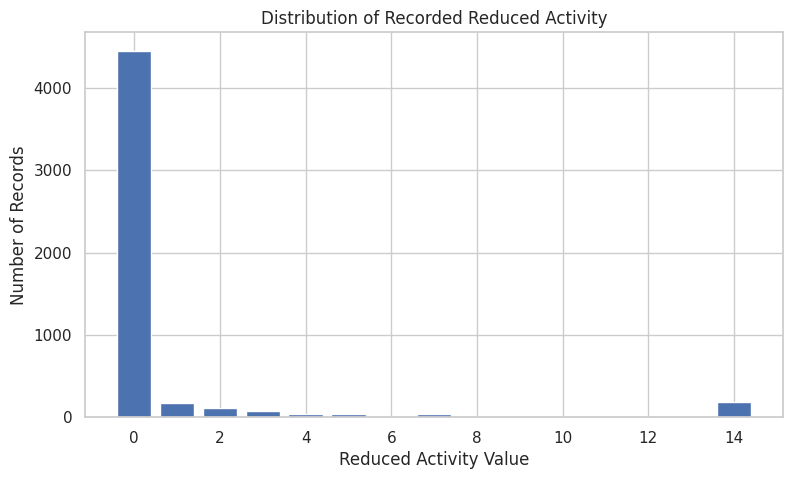

In [ ]:
#Visualization
reduced_counts = df_clean["reduced"].value_counts().sort_index()
plt.figure(figsize=(9, 5))
plt.bar(reduced_counts.index, reduced_counts.values)
plt.title("Distribution of Recorded Reduced Activity")
plt.xlabel("Reduced Activity Value")
plt.ylabel("Number of Records")
plt.show()

##Univariate Analysis : Health Distribution
This analysis examines the frequency and percentage of records in each recorded health-status category. It helps identify which codes are common and which are represented by relatively few records.

In [ ]:
df_clean['health'].value_counts().sort_index()

,count
health,
0,3026
1,823
2,446
3,273
4,187
5,132
6,104
7,61
8,42


In [ ]:
df_clean['health'].value_counts(normalize=True).sort_index() * 100

,proportion
health,
0,58.30
1,15.86
2,8.59
3,5.26
4,3.60
5,2.54
6,2.00
7,1.18
8,0.81


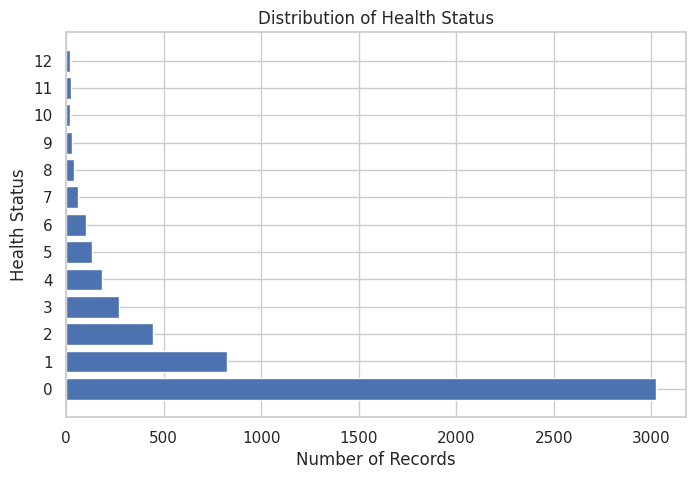

In [ ]:
#Visualization
health_counts = df_clean['health'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
plt.barh(health_counts.index.astype(str), health_counts.values)
plt.title('Distribution of Health Status')
plt.xlabel('Number of Records')
plt.ylabel('Health Status')
plt.show()

## Univariate Analysis: Chronic Condition Distribution
This analysis examines the frequency of records with and without the two recorded chronic-condition indicators. It helps describe how common each condition status is before comparing doctor visits across these groups.

##nchronic condition

In [ ]:
#nchronic
df_clean['nchronic'].value_counts()

,count
nchronic,
no,3098
yes,2092


In [ ]:
df_clean['nchronic'].value_counts(normalize=True) * 100

,proportion
nchronic,
no,59.69
yes,40.31


##lchronic condition

In [ ]:
#lchronic
df_clean['lchronic'].value_counts()

,count
lchronic,
no,4585
yes,605


In [ ]:
df_clean["lchronic"].value_counts(normalize=True) * 100

,proportion
lchronic,
no,88.34
yes,11.66


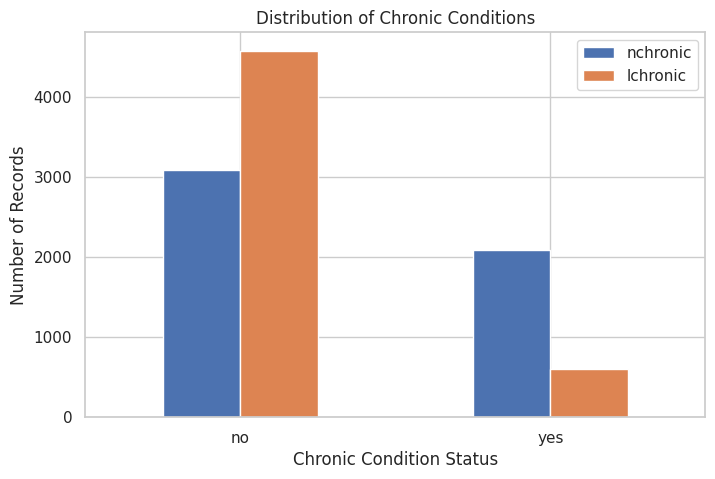

In [ ]:
# Visuaization
chronic_counts = pd.DataFrame({
    'nchronic': df_clean['nchronic'].value_counts(),
    'lchronic': df_clean['lchronic'].value_counts()
})

chronic_counts.plot(kind='bar', figsize=(8, 5))

plt.title('Distribution of Chronic Conditions')
plt.xlabel('Chronic Condition Status')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)

plt.show()

# Bivariate Analysis
Bivariate analysis examines the relationship between two variables. In your project, the main goal is to compare recorded doctor visits with gender, illness level, health code, and chronic-condition status.

## Bivariate Analysis: Gender vs Doctor Visits
This analysis compares recorded doctor visits across gender groups. It examines both the total number of visits and the average visits per record to distinguish overall totals from group-level averages.

In [ ]:
#calculate total visits by gender
gender_visits = df_clean.groupby('gender')['visits'].sum()
gender_visits

,visits
gender,
female,978
male,588


In [ ]:
#calculate total visits by gender
gender_avg_visits = df_clean.groupby('gender')['visits'].mean()
gender_avg_visits

,visits
gender,
female,0.36
male,0.24


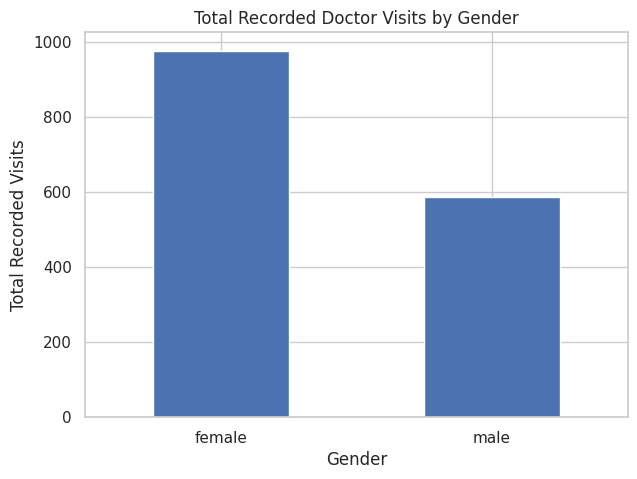

In [ ]:
# Visualization
plt.figure(figsize=(7,5))
gender_visits.plot(kind='bar')
plt.title('Total Recorded Doctor Visits by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Recorded Visits')
plt.xticks(rotation=0)
plt.show()

## Bivariate Analysis : Illness vs Doctor Visits
This analysis compares the number of records, total visits, and average visits across illness levels. It helps identify how recorded doctor visits vary between the illness categories.

In [ ]:
illness_visits = df_clean.groupby('illness')['visits'].agg(['count', 'sum', 'mean'])
illness_visits

,count,sum,mean
illness,,,
0,1554,122,0.08
1,1638,484,0.30
2,946,382,0.40
3,542,228,0.42
4,274,158,0.58
5,236,192,0.81


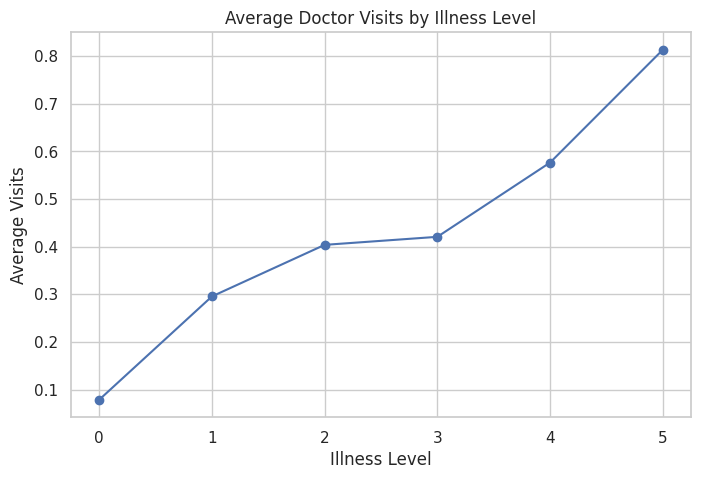

In [ ]:
# Visualization
plt.figure(figsize=(8,5))
plt.plot(
    illness_visits.index,
    illness_visits['mean'],
    marker='o'
)
plt.title('Average Doctor Visits by Illness Level')
plt.xlabel('Illness Level')
plt.ylabel('Average Visits')
plt.show()

## Bivariate Analysis : Health vs Doctor Visits
This analysis compares the number of records and average recorded doctor visits across health-status codes. It helps identify differences in visit averages between the recorded categories.


In [ ]:
# Calculate average visits by health status
health_visits = df_clean.groupby('health')['visits'].agg(['count', 'sum', 'mean'])
health_visits

,count,sum,mean
health,,,
0,3026,603,0.20
1,823,276,0.34
2,446,170,0.38
3,273,114,0.42
4,187,100,0.53
5,132,70,0.53
6,104,65,0.62
7,61,56,0.92
8,42,20,0.48


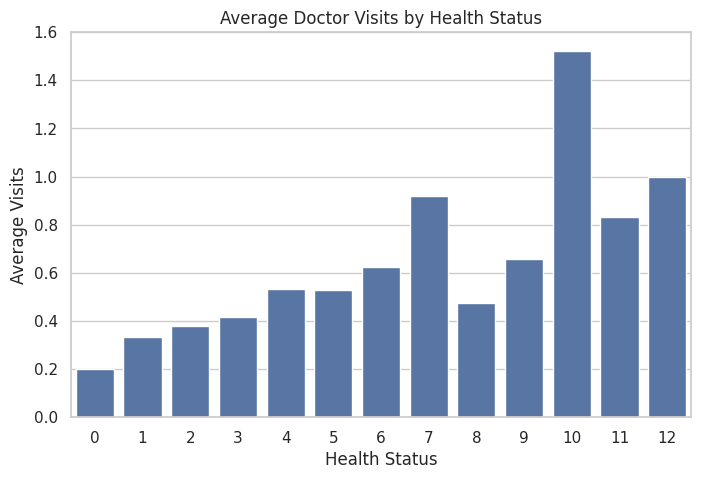

In [ ]:
# Visualization
plt.figure(figsize=(8,5))
sns.barplot(
    x=health_visits.index,
    y=health_visits['mean']
)
plt.title('Average Doctor Visits by Health Status')
plt.xlabel('Health Status')
plt.ylabel('Average Visits')
plt.show()

## Bivariate Analysis :Chronic Conditions vs Doctor Visits
This analysis compares the number of records, total visits, and average visits for records with and without each chronic-condition indicator. It helps assess whether recorded visit patterns differ by chronic-condition status.

In [ ]:
#for nchronic
nchronic_visits = df_clean.groupby('nchronic')['visits'].agg(['count', 'sum', 'mean'])
nchronic_visits

,count,sum,mean
nchronic,,,
no,3098,843,0.27
yes,2092,723,0.35


In [ ]:
# For lchronic
lchronic_visits = df_clean.groupby('lchronic')['visits'].agg(['count', 'sum', 'mean'])
lchronic_visits

,count,sum,mean
lchronic,,,
no,4585,1201,0.26
yes,605,365,0.60


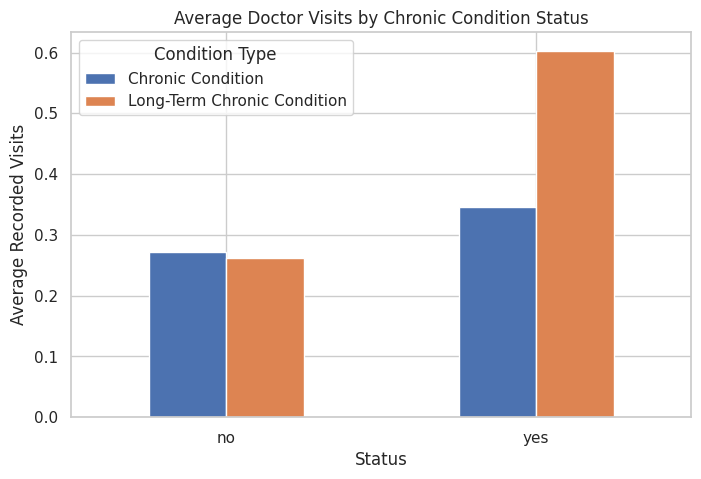

In [ ]:
# Visulazation
chronic_avg = pd.DataFrame({
    'Chronic Condition': nchronic_visits['mean'],
    'Long-Term Chronic Condition': lchronic_visits['mean']
})

chronic_avg.plot(
    kind='bar',
    figsize=(8, 5)
)
plt.title('Average Doctor Visits by Chronic Condition Status')
plt.xlabel('Status')
plt.ylabel('Average Recorded Visits')
plt.xticks(rotation=0)
plt.legend(title='Condition Type')
plt.show()

# Business Question Analysis

##Question: Which group has the most recorded doctor visits?

In [ ]:
gender_business_summary = (
    df_clean.groupby('gender')['visits']
    .agg(
        records='size',
        total_visits='sum',
        mean_visits='mean',
        median_visits='median'
    )
    .reset_index()
)

gender_business_summary['share_of_total_visits_pct'] = (
    gender_business_summary['total_visits']
    / df_clean['visits'].sum()
    * 100
)

display(gender_business_summary.round(2))

,gender,records,total_visits,mean_visits,median_visits,share_of_total_visits_pct
0,female,2702,978,0.36,0.00,62.45
1,male,2488,588,0.24,0.00,37.55


,gender,count,mean,median
0,female,2702,0.36,0.00
1,male,2488,0.24,0.00


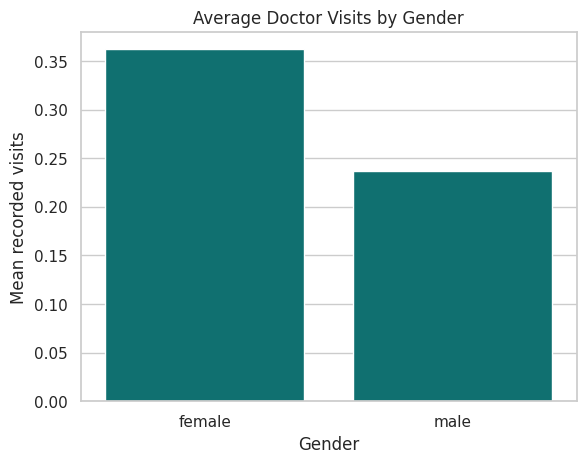

In [ ]:
#Visualization
gender_analysis = (
    df_clean.groupby("gender")["visits"]
      .agg(["count", "mean", "median"])
      .reset_index()
)
display(gender_analysis)

sns.barplot(
    data=gender_analysis,
    x="gender",
    y="mean",
    color="teal"
)
plt.title("Average Doctor Visits by Gender")
plt.xlabel("Gender")
plt.ylabel("Mean recorded visits")
plt.show()

##Interpretation    
The dataset contains 1,566 recorded doctor visits. Female records account for 978 visits (62.45%), while male records account for 588 visits (37.55%).

Female records therefore account for the larger share of recorded doctor visits in this dataset. This describes the observed totals and does not establish that gender itself causes differences in healthcare utilization.

# Question: How are illness and health status associated with doctor visits?

In [ ]:
illness_analysis = (
    df_clean.groupby('illness')['visits']
    .agg(['count', 'sum', 'mean'])
    .reset_index()
)

display(illness_analysis)

,illness,count,sum,mean
0,0,1554,122,0.08
1,1,1638,484,0.30
2,2,946,382,0.40
3,3,542,228,0.42
4,4,274,158,0.58
5,5,236,192,0.81


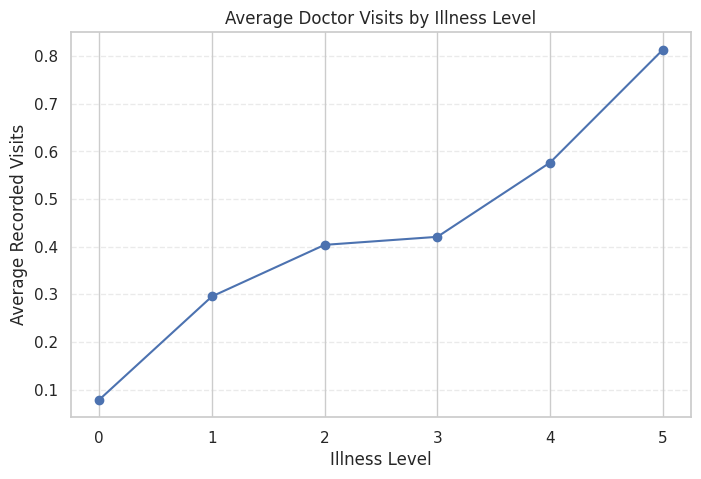

In [ ]:
# Visualization
plt.figure(figsize=(8, 5))
plt.plot(
    illness_analysis['illness'],
    illness_analysis['mean'],
    marker='o',
    linestyle='-'
)
plt.title('Average Doctor Visits by Illness Level')
plt.xlabel('Illness Level')
plt.ylabel('Average Recorded Visits')
plt.xticks(illness_analysis['illness'])
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

# Interpretation
The bivariate analysis shows that average recorded doctor visits vary across illness levels, increasing from approximately 0.08 at level 0 to 0.81 at level 5.

Average visits also vary across health-status codes. Code 10 has the highest average at approximately 1.52 visits, based on 21 records. Because this category is relatively small and the meaning of the health codes has not been verified, this result should be interpreted cautiously.

# Question: Do Chronic Conditions Correspond to Different Doctor Visit Patterns?

In [ ]:
#nchronic
nchronic_analysis = (
    df_clean.groupby('nchronic')['visits']
    .agg(['count', 'sum', 'mean', 'median'])
    .reset_index()
)

display(nchronic_analysis)

,nchronic,count,sum,mean,median
0,no,3098,843,0.27,0.00
1,yes,2092,723,0.35,0.00


In [ ]:
long_chronic_analysis = (
    df_clean.groupby('lchronic')['visits']
    .agg(['count', 'sum', 'mean', 'median'])
    .reset_index()
)

display(long_chronic_analysis)

,lchronic,count,sum,mean,median
0,no,4585,1201,0.26,0.00
1,yes,605,365,0.60,0.00


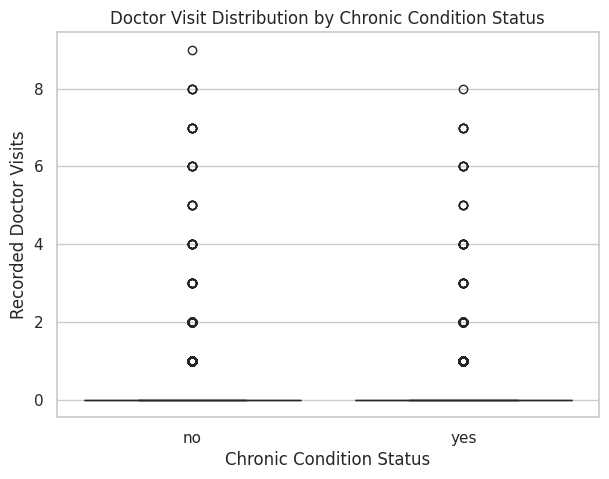

In [ ]:
#Visualization 1 — Chronic condition status
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df_clean,
    x='nchronic',
    y='visits',
    color='teal'
)
plt.title('Doctor Visit Distribution by Chronic Condition Status')
plt.xlabel('Chronic Condition Status')
plt.ylabel('Recorded Doctor Visits')
plt.show()

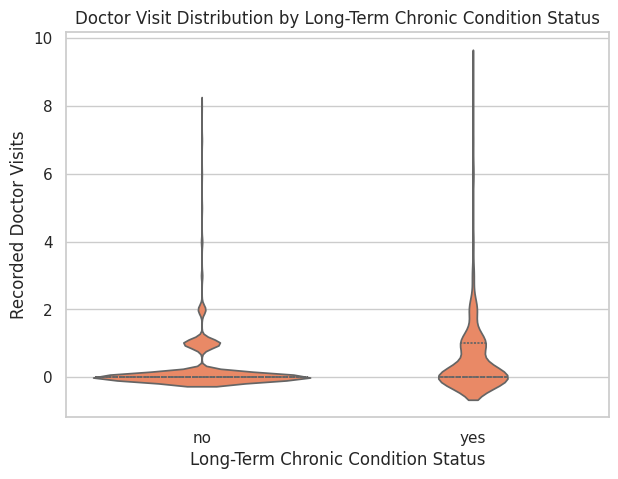

In [ ]:
#Visualization 2 — Long-term chronic condition status
plt.figure(figsize=(7, 5))
sns.violinplot(
    data=df_clean,
    x='lchronic',
    y='visits',
    color='coral',
    inner='quartile'
)
plt.title('Doctor Visit Distribution by Long-Term Chronic Condition Status')
plt.xlabel('Long-Term Chronic Condition Status')
plt.ylabel('Recorded Doctor Visits')
plt.show()

#Interpretation
The analysis shows differences in recorded doctor visit patterns according to chronic-condition status.

Records with chronic conditions had an average of 0.35 visits, compared with 0.27 visits among records without chronic conditions. Similarly, records with long-term chronic conditions had an average of 0.60 visits, compared with 0.26 visits among records without long-term chronic conditions.

Although both groups in each comparison had a median of zero visits, the higher average among records with chronic conditions—particularly long-term chronic conditions—suggests an association with higher recorded doctor visits. These findings describe associations and do not establish causation.

#Question: What Should Management Investigate Before Making Operational Changes?

In [ ]:
reduced_visits_corr = df_clean['reduced'].corr(
    df_clean['visits']
)

print(
    "Correlation between reduced activity and visits:",
    round(reduced_visits_corr, 3)
)

Correlation between reduced activity and visits: 0.419


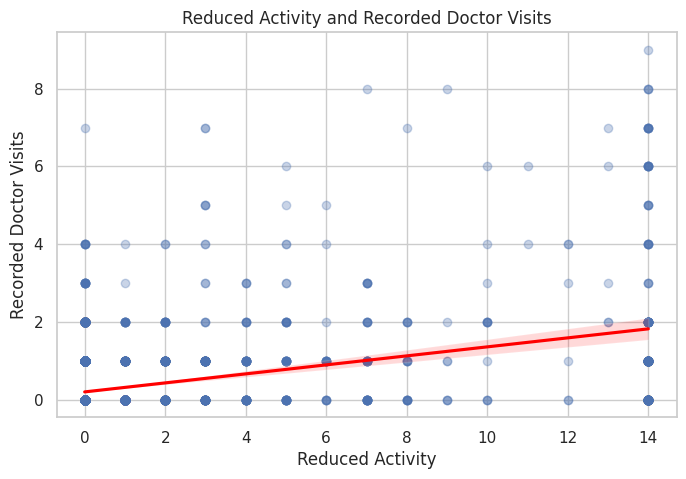

In [ ]:
# visulazation
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df_clean,
    x='reduced',
    y='visits',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)
plt.title('Reduced Activity and Recorded Doctor Visits')
plt.xlabel('Reduced Activity')
plt.ylabel('Recorded Doctor Visits')
plt.show()

# Interpretation
The correlation between reduced activity and recorded doctor visits is approximately 0.419, indicating a positive association in this dataset. The scatter plot and trend line also show an upward pattern in the recorded values.

Management should investigate what the reduced-activity variable represents and whether other factors may be related to both reduced activity and doctor visits. This correlation does not prove that reduced activity causes more doctor visits, and it should not be used alone to justify operational changes.

# Key Insights
1. **Dataset size:** The cleaned dataset contains 5,190 records and 12 columns used for analysis.
2. **Recorded visits:** The dataset contains 1,566 total recorded doctor visits.
3. **Zero visits:** 4,141 records (79.79%) have zero recorded visits.
4. **Gender:** Female records account for 978 visits, compared with 588 visits for male records.
5. **Illness:** Average visits range from 0.08 at illness level 0 to 0.81 at illness level 5.
6. **Chronic conditions:** Average visits are 0.35 for records with chronic conditions and 0.27 for records without them.
7. **Long-term chronic conditions:** Average visits are 0.60 for records with long-term chronic conditions and 0.26 for records without them.
8. **Reduced activity:** The analysis indicates a positive association between reduced activity and recorded doctor visits.

# Recommendations
Based on the analysis, the following recommendations are proposed:
1. **Investigate chronic conditions:** Examine the healthcare needs of patients with chronic and long-term chronic conditions, as these groups show higher average recorded doctor visits.
2. **Review illness and health patterns:** Explore differences in visits across illness levels and health-status categories to better understand healthcare utilization.
3. **Examine reduced activity:** Investigate the association between reduced activity and doctor visits to understand whether additional healthcare support may be needed.
4. **Review patient-group differences:** Examine differences in recorded visits across gender groups without assuming that gender itself explains those differences.
5. **Validate before making decisions:** Consider patient needs, healthcare access, resource availability, and additional evidence before making operational changes.

# Limitations
1. **Dataset scope:** The findings are based on the records available in this dataset and may not represent all patients or healthcare settings.
2. **Zero recorded visits:** A record with zero visits indicates no visits recorded in the dataset; it does not necessarily mean the person had no healthcare needs.
3. **Association, not causation:** The analysis identifies relationships between variables but cannot establish cause-and-effect relationships.
4. **Variable interpretation:** Some variables use coded categories, so their exact meanings and coding should be verified before drawing detailed conclusions.
5. **Limited context:** The dataset may not include all factors influencing doctor visits, such as healthcare availability, patient preferences, or other medical circumstances.

# Conclusion
This project analyzed healthcare data to understand patterns in recorded doctor visits. Using Python, Pandas, Matplotlib, and Seaborn, the dataset was explored, cleaned, summarized, and visualized.

The analysis identified differences in recorded visits across gender groups, illness levels, health-status categories, and chronic-condition groups. In particular, records associated with long-term chronic conditions showed a higher average number of recorded visits than records without such conditions.

The project demonstrates how exploratory data analysis and visualization can help identify patterns in healthcare utilization and highlight areas for further investigation. The findings provide useful descriptive insights, while additional evidence is required before drawing causal conclusions or making operational decisions.